In [19]:
#imports
import os
import re
import gc
import shutil
import copy
from tqdm import tqdm
from pathlib import Path
from typing import List, Dict, Tuple, Optional

import numpy as np
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report

import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import os
os.mkdir("/kaggle/working/Gravity_Spy_Multi_View_processed")

In [4]:
RAW_ROOT = "/kaggle/input/datasets/tentotheminus9/gravity-spy-gravitational-waves"
PROCESSED_ROOT = "/kaggle/working/Gravity_Spy_Multi_View_processed"

SPLITS = {
    "train": os.path.join(RAW_ROOT, "train", "train"),
    "validation": os.path.join(RAW_ROOT, "validation", "validation"),
    "test": os.path.join(RAW_ROOT, "test", "test"),
}

DURATIONS = [0.5, 1.0, 2.0, 4.0]
IMG_SIZE = (448, 448)
BATCH_SIZE = 32
EPOCHS = 100
LR = 2e-5
PATIENCE = 5
NUM_WORKERS = 2
LABEL_SMOOTHING = 0.3
WEIGHT_DECAY_BASE = 0.001
WEIGHT_DECAY_ATT = 0.01

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DURATION_RE = re.compile(r"_(0\.5|1\.0|2\.0|4\.0)\.png$", re.IGNORECASE)

# PREPROCESSING
def ensure_dir(path: str):
    Path(path).mkdir(parents=True, exist_ok=True)


def load_lines(path: str) -> List[str]:
    with open(path, "r") as f:
        return f.read().splitlines()


def extract_label_from_path(file_path: str) -> str:
    return Path(file_path).parent.name


def extract_sample_id_and_duration(filename: str):
    m = DURATION_RE.search(filename)
    if not m:
        return None, None
    duration = float(m.group(1))
    sample_id = filename[:m.start()]
    return sample_id, duration


def sort_key(file_path: str) -> str:
    filename = os.path.basename(file_path)
    sample_id, _ = extract_sample_id_and_duration(filename)
    return sample_id if sample_id is not None else filename


def get_all_image_files(split_root: str) -> List[str]:
    files = []
    for class_name in sorted(os.listdir(split_root)):
        class_dir = os.path.join(split_root, class_name)
        if not os.path.isdir(class_dir):
            continue
        for fname in os.listdir(class_dir):
            if fname.lower().endswith(".png"):
                files.append(os.path.join(class_dir, fname))
    return files


def categorize_file_paths(file_paths: List[str], duration_categories: List[float]) -> Dict[float, List[str]]:
    categorized_paths = {duration: [] for duration in duration_categories}
    for file_path in file_paths:
        filename = os.path.basename(file_path)
        _, duration = extract_sample_id_and_duration(filename)
        if duration is None:
            continue
        if duration in categorized_paths:
            categorized_paths[duration].append(file_path)
    return categorized_paths


def write_labels_to_file(labels: List[str], file_path: str):
    ensure_dir(os.path.dirname(file_path))
    with open(file_path, "w") as f:
        for label in labels:
            f.write(f"{label}\n")


def process_and_save_images(input_files: List[str], output_dir: str):
    ensure_dir(output_dir)
    for input_path in input_files:
        class_name = extract_label_from_path(input_path)
        filename = os.path.basename(input_path)
        out_path = os.path.join(output_dir, class_name, filename)
        ensure_dir(os.path.dirname(out_path))

        img = Image.open(input_path).convert("RGB")
        img = img.resize(IMG_SIZE, Image.BILINEAR)
        img.save(out_path, format="PNG")


def move_files_to_duration_folders(file_paths_by_duration: Dict[float, List[str]], split_output_root: str):
    for duration, paths in file_paths_by_duration.items():
        duration_dir = os.path.join(split_output_root, "duration", str(duration))
        ensure_dir(duration_dir)

        sorted_paths = sorted(paths, key=sort_key)
        for file_path in sorted_paths:
            class_name = extract_label_from_path(file_path)
            filename = os.path.basename(file_path)

            src = file_path
            dst = os.path.join(duration_dir, class_name, filename)
            ensure_dir(os.path.dirname(dst))
            shutil.copy2(src, dst)


def build_split_pipeline(split_name: str, split_input_root: str):
    print(f"Processing split: {split_name}")

    all_files = get_all_image_files(split_input_root)
    duration_paths = categorize_file_paths(all_files, DURATIONS)

    for d in DURATIONS:
        duration_paths[d] = sorted(duration_paths[d], key=sort_key)

    labels = [extract_label_from_path(p) for p in duration_paths[DURATIONS[0]]]

    split_output_root = os.path.join(PROCESSED_ROOT, split_name)
    ensure_dir(split_output_root)

    label_file = os.path.join(split_output_root, f"{split_name}_labels.txt")
    write_labels_to_file(labels, label_file)

    move_files_to_duration_folders(duration_paths, split_output_root)

    for d in DURATIONS:
        print(f"  Duration {d}: {len(duration_paths[d])} files")
    print(f"  Labels written to: {label_file}")


for split_name, split_input_root in SPLITS.items():
    build_split_pipeline(split_name, split_input_root)

print("Preprocessing complete.")

Processing split: train
  Duration 0.5: 5587 files
  Duration 1.0: 5587 files
  Duration 2.0: 5587 files
  Duration 4.0: 5587 files
  Labels written to: /kaggle/working/Gravity_Spy_Multi_View_processed/train/train_labels.txt
Processing split: validation
  Duration 0.5: 1200 files
  Duration 1.0: 1200 files
  Duration 2.0: 1200 files
  Duration 4.0: 1200 files
  Labels written to: /kaggle/working/Gravity_Spy_Multi_View_processed/validation/validation_labels.txt
Processing split: test
  Duration 0.5: 1180 files
  Duration 1.0: 1180 files
  Duration 2.0: 1180 files
  Duration 4.0: 1180 files
  Labels written to: /kaggle/working/Gravity_Spy_Multi_View_processed/test/test_labels.txt
Preprocessing complete.


In [18]:
#Dataset for Multiview arrangement
class MultiViewDataset(Dataset):
    def __init__(self, root_dir: str, labels: Optional[List[int]] = None, transform=None):
        self.root_dir = Path(root_dir)
        self.labels = torch.tensor(labels, dtype=torch.long) if labels is not None else None
        self.transform = transform or transforms.Compose([
            transforms.Resize(IMG_SIZE),
            transforms.ToTensor(),
        ])

        self.duration_dirs = [
            self.root_dir / "duration" / str(d) for d in DURATIONS
        ]
        for d in self.duration_dirs:
            print(d, len(list(d.rglob("*.png"))))

        self.files_by_duration = []
        self.sample_ids_by_duration = []

        for d in self.duration_dirs:
            files = sorted([p for p in d.rglob("*.png")], key=lambda p: sort_key(str(p)))
            ids = []
            for f in files:
                fname = f.name
                m = DURATION_RE.search(fname)
                if not m:
                    raise ValueError(f"Filename does not match expected pattern: {fname}")
                ids.append(fname[:m.start()])
            self.files_by_duration.append(files)
            self.sample_ids_by_duration.append(ids)

        ref_ids = self.sample_ids_by_duration[0]
        for ids in self.sample_ids_by_duration[1:]:
            if ids != ref_ids:
                raise ValueError(f"Duration folders in split '{split}' are not aligned by sample id.")

        self.sample_ids = ref_ids
        self.num_samples = len(self.sample_ids)

        if self.labels is not None and len(self.labels) != self.num_samples:
            raise ValueError(f"Labels length ({len(self.labels)}) does not match samples ({self.num_samples}).")

    def __len__(self):
        return self.num_samples

    def __getitem__(self, idx):
        views = []
        for files in self.files_by_duration:
            img_path = files[idx]
            image = Image.open(img_path).convert("RGB")
            image = self.transform(image)
            views.append(image)

        if self.labels is None:
            return tuple(views)
        return tuple(views), self.labels[idx]


# Building Model
class InceptionResNetModule(nn.Module):
    def __init__(self, in_channels: int, num_feature_maps: int):
        super().__init__()
        out_c = num_feature_maps

        self.tower_1 = nn.Sequential(
            nn.Conv2d(in_channels, out_c, kernel_size=1, padding=0, bias=True),
            nn.ReLU()
        )
        self.tower_2 = nn.Sequential(
            nn.Conv2d(in_channels, out_c, kernel_size=1, padding=0, bias=True),
            nn.ReLU(),
            nn.Conv2d(out_c, out_c, kernel_size=3, padding=1, bias=True),
            nn.ReLU()
        )
        self.tower_3 = nn.Sequential(
            nn.Conv2d(in_channels, out_c, kernel_size=1, padding=0, bias=True),
            nn.ReLU(),
            nn.Conv2d(out_c, out_c, kernel_size=5, padding=2, bias=True),
            nn.ReLU()
        )
        self.tower_4_pool = nn.MaxPool2d(kernel_size=3, stride=1, padding=1)
        self.tower_4_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_c, kernel_size=1, padding=0, bias=True),
            nn.ReLU()
        )
        self.shortcut = nn.Conv2d(in_channels, out_c * 4, kernel_size=1, padding=0, bias=True)

    def forward(self, x):
        t1 = self.tower_1(x)
        t2 = self.tower_2(x)
        t3 = self.tower_3(x)
        t4 = self.tower_4_conv(self.tower_4_pool(x))
        out = torch.cat([t1, t2, t3, t4], dim=1)
        return F.relu(out + self.shortcut(x))


class BaselineCNN(nn.Module):
    def __init__(self, in_channels: int = 3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(in_channels, 16, kernel_size=5, padding=0),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=3),

            nn.Conv2d(16, 32, kernel_size=5, padding=0),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            InceptionResNetModule(32, 16),

            nn.Conv2d(64, 64, kernel_size=5, padding=0),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            InceptionResNetModule(64, 16),

            nn.Conv2d(64, 64, kernel_size=5, padding=0),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            InceptionResNetModule(64, 32),

            nn.Conv2d(128, 128, kernel_size=5, padding=0),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Dropout(0.25),
        )

        with torch.no_grad():
            dummy = torch.zeros(1, 3, IMG_SIZE[0], IMG_SIZE[1])
            flat_dim = int(np.prod(self.features(dummy).shape))

        self.fc = nn.Sequential(
            nn.Linear(flat_dim, 128),
            nn.ReLU()
        )

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x.unsqueeze(1)


class GatedAttentionLayer(nn.Module):
    def __init__(self, input_dim: int = 128, weight_dim: int = 64):
        super().__init__()
        self.v = nn.Parameter(torch.empty(input_dim, weight_dim))
        self.u = nn.Parameter(torch.empty(input_dim, weight_dim))
        self.w = nn.Parameter(torch.empty(weight_dim, 1))
        nn.init.xavier_uniform_(self.v)
        nn.init.xavier_uniform_(self.u)
        nn.init.xavier_uniform_(self.w)

    def forward(self, inputs):
        tanh_term = torch.tanh(torch.matmul(inputs, self.v))
        sigmoid_term = torch.sigmoid(torch.matmul(inputs, self.u))
        gated_term = tanh_term * sigmoid_term
        scores = torch.matmul(gated_term, self.w)
        return F.softmax(scores, dim=1)


class GSMultiViewNet(nn.Module):
    def __init__(self, nb_classes: int):
        super().__init__()
        self.branch_0_5 = BaselineCNN()
        self.branch_1_0 = BaselineCNN()
        self.branch_2_0 = BaselineCNN()
        self.branch_4_0 = BaselineCNN()
        self.attention = GatedAttentionLayer(input_dim=128, weight_dim=64)
        self.last_layer = nn.Linear(128, nb_classes)

    def forward(self, views):
        v05, v10, v20, v40 = views
        c05 = self.branch_0_5(v05)
        c10 = self.branch_1_0(v10)
        c20 = self.branch_2_0(v20)
        c40 = self.branch_4_0(v40)

        concat = torch.cat([c05, c10, c20, c40], dim=1)
        att = self.attention(concat)
        intermediate = torch.matmul(att.transpose(1, 2), concat).squeeze(1)
        return self.last_layer(intermediate)



/kaggle/working/Gravity_Spy_Multi_View_processed/train/duration/0.5 5587
/kaggle/working/Gravity_Spy_Multi_View_processed/train/duration/1.0 5587
/kaggle/working/Gravity_Spy_Multi_View_processed/train/duration/2.0 5587
/kaggle/working/Gravity_Spy_Multi_View_processed/train/duration/4.0 5587
/kaggle/working/Gravity_Spy_Multi_View_processed/validation/duration/0.5 1200
/kaggle/working/Gravity_Spy_Multi_View_processed/validation/duration/1.0 1200
/kaggle/working/Gravity_Spy_Multi_View_processed/validation/duration/2.0 1200
/kaggle/working/Gravity_Spy_Multi_View_processed/validation/duration/4.0 1200
/kaggle/working/Gravity_Spy_Multi_View_processed/test/duration/0.5 1180
/kaggle/working/Gravity_Spy_Multi_View_processed/test/duration/1.0 1180
/kaggle/working/Gravity_Spy_Multi_View_processed/test/duration/2.0 1180
/kaggle/working/Gravity_Spy_Multi_View_processed/test/duration/4.0 1180
Epoch 001/100 | train_loss=2.2872 train_acc=0.5926 | val_loss=1.8848 val_acc=0.8175
Epoch 002/100 | train_lo

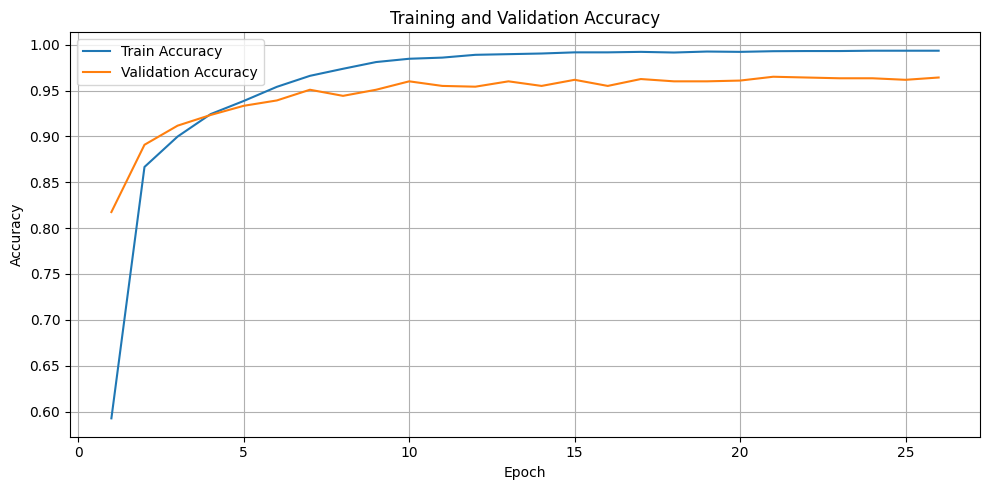

Test loss: 1.5669
Test accuracy: 0.9619


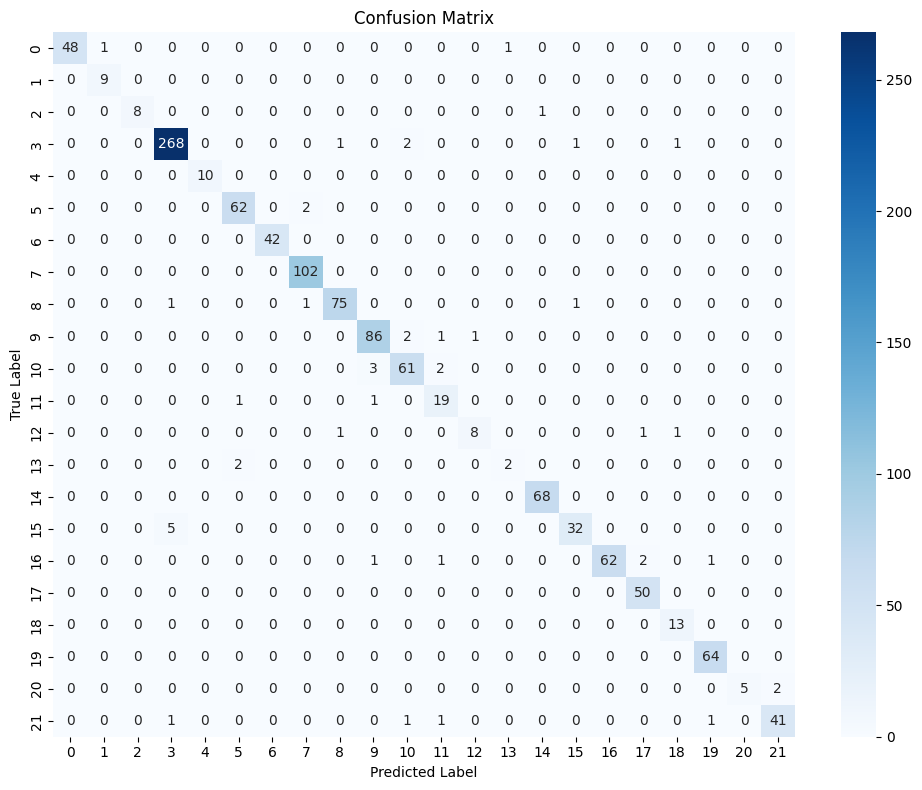

Classification Report:
                      precision    recall  f1-score   support

          1080Lines     1.0000    0.9600    0.9796        50
        1400Ripples     0.9000    1.0000    0.9474         9
     Air_Compressor     1.0000    0.8889    0.9412         9
               Blip     0.9745    0.9817    0.9781       273
              Chirp     1.0000    1.0000    1.0000        10
     Extremely_Loud     0.9538    0.9688    0.9612        64
              Helix     1.0000    1.0000    1.0000        42
           Koi_Fish     0.9714    1.0000    0.9855       102
   Light_Modulation     0.9740    0.9615    0.9677        78
Low_Frequency_Burst     0.9451    0.9556    0.9503        90
Low_Frequency_Lines     0.9242    0.9242    0.9242        66
          No_Glitch     0.7917    0.9048    0.8444        21
  None_of_the_Above     0.8889    0.7273    0.8000        11
       Paired_Doves     0.6667    0.5000    0.5714         4
         Power_Line     0.9855    1.0000    0.9927        68

In [19]:
#Train and evaluation definitions so its easier to call
def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for views, labels in loader:
        views = tuple(v.to(device) for v in views)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(views)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total


@torch.no_grad()
def eval_epoch(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0

    for views, labels in loader:
        views = tuple(v.to(device) for v in views)
        labels = labels.to(device)

        outputs = model(views)
        loss = criterion(outputs, labels)

        total_loss += loss.item() * labels.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total


@torch.no_grad()
def predict(model, loader, device):
    model.eval()
    all_true, all_pred = [], []

    for views, labels in loader:
        views = tuple(v.to(device) for v in views)
        outputs = model(views)
        preds = outputs.argmax(dim=1).cpu().numpy()

        all_pred.extend(preds.tolist())
        all_true.extend(labels.numpy().tolist())

    return np.array(all_true), np.array(all_pred)

# MAIN!!!!!
def main():
    train_acc_history = []
    val_acc_history = []
    train_loss_history = []
    val_loss_history = []
    train_labels_raw = load_lines(f"{PROCESSED_ROOT}/train/train_labels.txt")
    val_labels_raw = load_lines(f"{PROCESSED_ROOT}/validation/validation_labels.txt")
    test_labels_raw = load_lines(f"{PROCESSED_ROOT}/test/test_labels.txt")

    label_encoder = LabelEncoder()
    y_train = label_encoder.fit_transform(train_labels_raw)
    y_val = label_encoder.transform(val_labels_raw)
    y_test = label_encoder.transform(test_labels_raw)

    nb_classes = len(label_encoder.classes_)

    train_ds = MultiViewDataset(f"{PROCESSED_ROOT}/train", labels=y_train)
    val_ds = MultiViewDataset(f"{PROCESSED_ROOT}/validation", labels=y_val)
    test_ds = MultiViewDataset(f"{PROCESSED_ROOT}/test", labels=y_test)
    
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
    test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

    model = GSMultiViewNet(nb_classes=nb_classes).to(DEVICE)

    criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)

    attention_params = []
    base_params = []
    for name, param in model.named_parameters():
        if "attention" in name:
            attention_params.append(param)
        else:
            base_params.append(param)

    optimizer = torch.optim.Adam(
        [
            {"params": base_params, "weight_decay": WEIGHT_DECAY_BASE},
            {"params": attention_params, "weight_decay": WEIGHT_DECAY_ATT},
        ],
        lr=LR
    )

    best_val_acc = 0.0
    patience_counter = 0
    best_path = "best_mv_model.pth"

    for epoch in range(EPOCHS):
        train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, DEVICE)
        val_loss, val_acc = eval_epoch(model, val_loader, criterion, DEVICE)
        train_acc_history.append(train_acc)
        val_acc_history.append(val_acc)
        train_loss_history.append(train_loss)
        val_loss_history.append(val_loss)

        print(
            f"Epoch {epoch+1:03d}/{EPOCHS} | "
            f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
            f"val_loss={val_loss:.4f} val_acc={val_acc:.4f}"
        )

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            patience_counter = 0
            torch.save(model.state_dict(), best_path)
        else:
            patience_counter += 1
            if patience_counter >= PATIENCE:
                print(f"Early stopping triggered at epoch {epoch+1}.")
                break

    model.load_state_dict(torch.load(best_path, map_location=DEVICE, weights_only=True))

    epochs_range = range(1, len(train_acc_history) + 1)

    plt.figure(figsize=(10, 5))
    plt.plot(epochs_range, train_acc_history, label="Train Accuracy")
    plt.plot(epochs_range, val_acc_history, label="Validation Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title("Training and Validation Accuracy")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig("accuracy_curve.png", dpi=300)
    plt.show()

    test_loss, test_acc = eval_epoch(model, test_loader, criterion, DEVICE)
    print(f"Test loss: {test_loss:.4f}")
    print(f"Test accuracy: {test_acc:.4f}")

    y_true, y_pred = predict(model, test_loader, DEVICE)

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=np.arange(nb_classes), yticklabels=np.arange(nb_classes))
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.title("Confusion Matrix")
    plt.tight_layout()
    plt.show()

    report = classification_report(
        y_true,
        y_pred,
        target_names=[str(c) for c in label_encoder.classes_],
        digits=4
    )
    print("Classification Report:\n", report)

    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


if __name__ == "__main__":
    main()

# **Comparison models: VGG19 and Inception Residual Network**

In [20]:
class SingleViewDataset(Dataset):
    def __init__(self, root_dir, duration="0.5", transform=None, label_encoder=None):
        self.root_dir = Path(root_dir) / "duration" / str(duration)
        self.transform = transform
        self.label_encoder = label_encoder

        self.samples = []
        class_names = sorted([d.name for d in self.root_dir.iterdir() if d.is_dir()])
        for cls in class_names:
            for img_path in sorted((self.root_dir / cls).glob("*.png")):
                self.samples.append((str(img_path), cls))

        self.classes = class_names
        if self.label_encoder is not None:
            self.label_map = {c: i for i, c in enumerate(self.label_encoder.classes_)}
        else:
            self.label_map = {c: i for i, c in enumerate(self.classes)}

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, cls = self.samples[idx]
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        label = self.label_map[cls]
        return image, torch.tensor(label, dtype=torch.long)


In [21]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in tqdm(loader, leave=False):
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, correct / total

@torch.no_grad()
def eval_one_epoch(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in tqdm(loader, leave=False):
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        outputs = model(images)
        loss = criterion(outputs, labels)

        total_loss += loss.item() * labels.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, correct / total

def fit_model(model, train_loader, val_loader, num_epochs=15, lr=1e-4, save_path="best_model.pth"):
    model = model.to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    best_val_acc = 0.0
    best_state = copy.deepcopy(model.state_dict())

    train_loss_hist, val_loss_hist = [], []
    train_acc_hist, val_acc_hist = [], []

    for epoch in range(num_epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc = eval_one_epoch(model, val_loader, criterion)

        train_loss_hist.append(train_loss)
        val_loss_hist.append(val_loss)
        train_acc_hist.append(train_acc)
        val_acc_hist.append(val_acc)

        print(f"Epoch {epoch+1:03d}/{num_epochs} | train_loss={train_loss:.4f} train_acc={train_acc:.4f} | val_loss={val_loss:.4f} val_acc={val_acc:.4f}")

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = copy.deepcopy(model.state_dict())
            torch.save(best_state, save_path)

    model.load_state_dict(best_state)
    return model, train_loss_hist, val_loss_hist, train_acc_hist, val_acc_hist

def plot_history(train_acc_hist, val_acc_hist, train_loss_hist, val_loss_hist, prefix):
    epochs = range(1, len(train_acc_hist) + 1)

    plt.figure(figsize=(8,5))
    plt.plot(epochs, train_acc_hist, label="Train Accuracy")
    plt.plot(epochs, val_acc_hist, label="Validation Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"{prefix}_accuracy.png", dpi=300)
    plt.show()

    plt.figure(figsize=(8,5))
    plt.plot(epochs, train_loss_hist, label="Train Loss")
    plt.plot(epochs, val_loss_hist, label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"{prefix}_loss.png", dpi=300)
    plt.show()

In [22]:
train_labels_raw = load_lines(f"{PROCESSED_ROOT}/train/train_labels.txt")
val_labels_raw = load_lines(f"{PROCESSED_ROOT}/validation/validation_labels.txt")
test_labels_raw = load_lines(f"{PROCESSED_ROOT}/test/test_labels.txt")

label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(train_labels_raw)
y_val = label_encoder.transform(val_labels_raw)
y_test = label_encoder.transform(test_labels_raw)

Downloading: "https://download.pytorch.org/models/vgg19-dcbb9e9d.pth" to /root/.cache/torch/hub/checkpoints/vgg19-dcbb9e9d.pth


100%|██████████| 548M/548M [00:02<00:00, 204MB/s] 


Epoch 001/30 | train_loss=0.9362 train_acc=0.7394 | val_loss=0.4797 val_acc=0.8642


Epoch 002/30 | train_loss=0.4103 train_acc=0.8838 | val_loss=0.3336 val_acc=0.9000


Epoch 003/30 | train_loss=0.2904 train_acc=0.9184 | val_loss=0.2467 val_acc=0.9225


...

Epoch 026/30 | train_loss=0.0465 train_acc=0.9871 | val_loss=0.3868 val_acc=0.9083


Epoch 027/30 | train_loss=0.0700 train_acc=0.9817 | val_loss=0.3927 val_acc=0.9275


Epoch 028/30 | train_loss=0.0422 train_acc=0.9896 | val_loss=0.3881 val_acc=0.9333


Epoch 029/30 | train_loss=0.0412 train_acc=0.9882 | val_loss=0.3479 val_acc=0.9358


Epoch 030/30 | train_loss=0.0522 train_acc=0.9855 | val_loss=0.3577 val_acc=0.9375


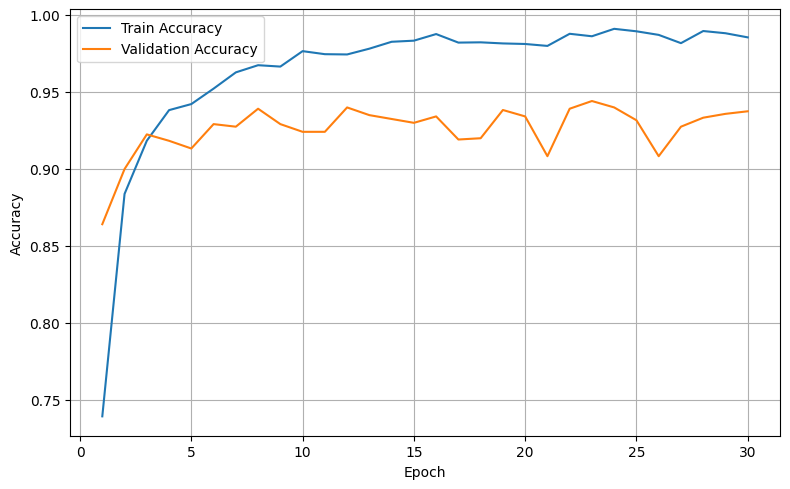

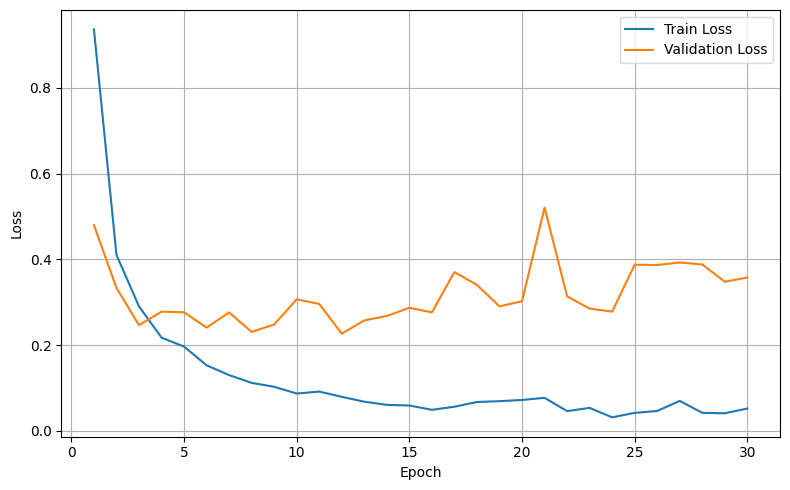

In [7]:
from torchvision import models

def build_vgg19(num_classes):
    weights = models.VGG19_Weights.IMAGENET1K_V1
    model = models.vgg19(weights=weights)

    for p in model.features.parameters():
        p.requires_grad = False

    in_features = model.classifier[6].in_features
    model.classifier[6] = nn.Linear(in_features, num_classes)
    return model

vgg_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

train_ds_vgg = SingleViewDataset(f"{PROCESSED_ROOT}/train", duration="0.5", transform=vgg_transform, label_encoder=label_encoder)
val_ds_vgg = SingleViewDataset(f"{PROCESSED_ROOT}/validation", duration="0.5", transform=vgg_transform, label_encoder=label_encoder)
test_ds_vgg = SingleViewDataset(f"{PROCESSED_ROOT}/test", duration="0.5", transform=vgg_transform, label_encoder=label_encoder)

train_loader_vgg = DataLoader(train_ds_vgg, batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
val_loader_vgg = DataLoader(val_ds_vgg, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)
test_loader_vgg = DataLoader(test_ds_vgg, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

vgg19_model = build_vgg19(num_classes=len(label_encoder.classes_))
vgg19_model, train_loss_hist, val_loss_hist, train_acc_hist, val_acc_hist = fit_model(
    vgg19_model,
    train_loader_vgg,
    val_loader_vgg,
    num_epochs=30,
    lr=1e-4,
    save_path="vgg19_best.pth"
)

plot_history(train_acc_hist, val_acc_hist, train_loss_hist, val_loss_hist, prefix="vgg19")

In [9]:
@torch.no_grad()
def test_model(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_true, all_pred = [], []

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        logits = outputs.logits if hasattr(outputs, "logits") else outputs
        loss = criterion(logits, labels)

        total_loss += loss.item() * labels.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

        all_true.extend(labels.cpu().numpy())
        all_pred.extend(preds.cpu().numpy())

    return total_loss / total, correct / total, np.array(all_true), np.array(all_pred)

vgg19_model.eval()
criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
test_loss, test_acc, y_true, y_pred = test_model(
    vgg19_model,
    test_loader_vgg,
    criterion,
    DEVICE
)

print(f"VGG19 Test loss: {test_loss:.4f}")
print(f"VGG19 Test accuracy: {test_acc:.4f}")

VGG19 Test loss: 7.1986
VGG19 Test accuracy: 0.9220


IncepteionV3

In [23]:
#modified train and eval for inception due to aux logits error
def get_logits(outputs):
    if hasattr(outputs, "logits"):
        return outputs.logits
    if isinstance(outputs, tuple):
        return outputs[0]
    return outputs
    
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for images, labels in loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()
        outputs = model(images)
        logits = get_logits(outputs)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total


@torch.no_grad()
def eval_one_epoch(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0

    for images, labels in loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = model(images)
        logits = get_logits(outputs)
        loss = criterion(logits, labels)

        total_loss += loss.item() * labels.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total

Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 189MB/s]  


Epoch 001/30 | train_loss=1.5186 train_acc=0.5935 | val_loss=0.9424 val_acc=0.7433
Epoch 002/30 | train_loss=0.9242 train_acc=0.7448 | val_loss=0.7604 val_acc=0.7892
Epoch 003/30 | train_loss=0.7702 train_acc=0.7868 | val_loss=0.6541 val_acc=0.8233
Epoch 004/30 | train_loss=0.7068 train_acc=0.7934 | val_loss=0.6288 val_acc=0.8325
Epoch 005/30 | train_loss=0.6493 train_acc=0.8074 | val_loss=0.5914 val_acc=0.8225
Epoch 006/30 | train_loss=0.6265 train_acc=0.8144 | val_loss=0.5534 val_acc=0.8425
Epoch 007/30 | train_loss=0.5971 train_acc=0.8219 | val_loss=0.5489 val_acc=0.8450
Epoch 008/30 | train_loss=0.5710 train_acc=0.8285 | val_loss=0.5243 val_acc=0.8492
Epoch 009/30 | train_loss=0.5755 train_acc=0.8292 | val_loss=0.5200 val_acc=0.8442
Epoch 010/30 | train_loss=0.5509 train_acc=0.8337 | val_loss=0.5246 val_acc=0.8425
Epoch 011/30 | train_loss=0.5470 train_acc=0.8269 | val_loss=0.5061 val_acc=0.8500
Epoch 012/30 | train_loss=0.5337 train_acc=0.8378 | val_loss=0.4924 val_acc=0.8592
Epoc

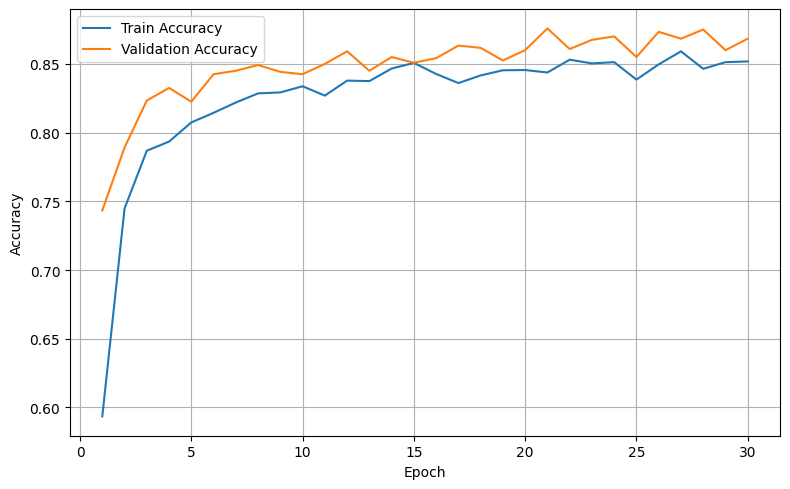

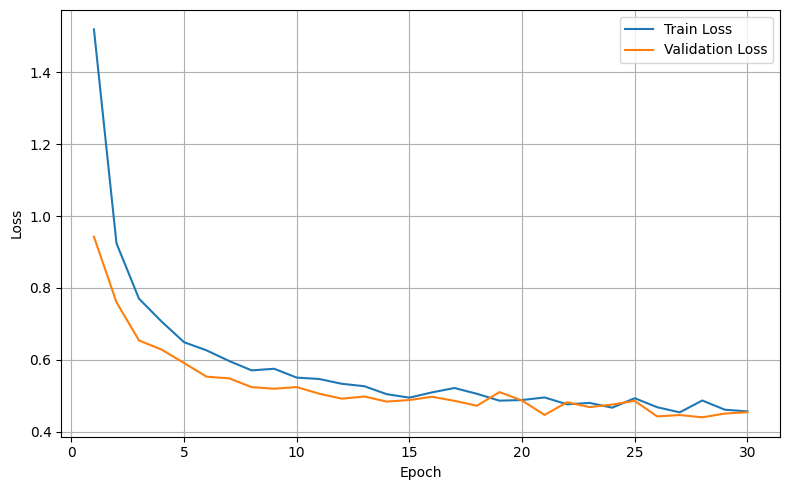

In [25]:
from torchvision import models
def build_inception_v3(num_classes):
    weights = models.Inception_V3_Weights.IMAGENET1K_V1
    model = models.inception_v3(weights=weights, aux_logits=True)

    for p in model.parameters():
        p.requires_grad = False

    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, num_classes)

    if model.AuxLogits is not None:
        aux_in_features = model.AuxLogits.fc.in_features
        model.AuxLogits.fc = nn.Linear(aux_in_features, num_classes)

    return model
    
inception_transform = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])
train_ds_inc = SingleViewDataset(f"{PROCESSED_ROOT}/train", duration="0.5", transform=inception_transform, label_encoder=label_encoder)
val_ds_inc = SingleViewDataset(f"{PROCESSED_ROOT}/validation", duration="0.5", transform=inception_transform, label_encoder=label_encoder)
test_ds_inc = SingleViewDataset(f"{PROCESSED_ROOT}/test", duration="0.5", transform=inception_transform, label_encoder=label_encoder)

train_loader_inc = DataLoader(train_ds_inc, batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
val_loader_inc = DataLoader(val_ds_inc, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)
test_loader_inc = DataLoader(test_ds_inc, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

inception_model = build_inception_v3(num_classes=len(label_encoder.classes_))
inception_model, train_loss_hist, val_loss_hist, train_acc_hist, val_acc_hist = fit_model(
    inception_model,
    train_loader_inc,
    val_loader_inc,
    num_epochs=30,
    lr=1e-3,
    save_path="inception_best.pth"
)

plot_history(train_acc_hist, val_acc_hist, train_loss_hist, val_loss_hist, prefix="inception")

In [27]:
@torch.no_grad()
def test_model(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_true, all_pred = [], []

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        logits = outputs.logits if hasattr(outputs, "logits") else outputs
        loss = criterion(logits, labels)

        total_loss += loss.item() * labels.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

        all_true.extend(labels.cpu().numpy())
        all_pred.extend(preds.cpu().numpy())

    return total_loss / total, correct / total, np.array(all_true), np.array(all_pred)
inception_model.eval()
criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
test_loss, test_acc, y_true, y_pred = test_model(
    inception_model,
    test_loader_inc,
    criterion,
    DEVICE
)

print(f"InceptionV3 Test loss: {test_loss:.4f}")
print(f"InceptionV3 Test accuracy: {test_acc:.4f}")

InceptionV3 Test loss: 3.1220
InceptionV3 Test accuracy: 0.8686
